# NILM Phase 3 — CNN + BiLSTM + Temporal Attention + Enhanced Knowledge Fusion (21-D)
**Dataset:** UK-DALE 2017, House 1
**Appliances:** Dishwasher, Washing Machine, Laptop, Fridge, Office Lamp 1

This notebook is fully self-contained: mounts Drive, loads House 1 channels, builds the
aggregate signal from the 5 selected appliances, preprocesses, generates sliding windows,
computes a 21-dimensional window-level knowledge vector, trains a CNN+BiLSTM+Attention
model with attention-gated knowledge fusion and a knowledge-reconstruction auxiliary head,
evaluates per-appliance precision/recall/F1/accuracy, and estimates active-time error.

**Knowledge vector (21-D):**
Original 12: mean_power, max_power, min_power, std_power, power_jump, num_transitions,
dominant_period, rise_time, fall_time, duty_cycle, rms_power, range_power

New 9 (all signal-derived, leakage-safe): energy_per_window, max_positive_delta,
max_negative_delta, mean_absolute_delta, median_power, iqr_power, autocorr_peak_strength,
skewness, kurtosis

All 21 features are computed purely from the aggregate window itself (never from appliance
ground truth), so they are safe to compute identically on train/val/test with no leakage.


## 1. Install Dependencies

In [ ]:
!pip install -q tensorflow scikit-learn scipy pandas numpy matplotlib seaborn

## 2. Import Libraries

In [ ]:
import os
import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import medfilt
from scipy.stats import skew, kurtosis as kurtosis_fn
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (precision_score, recall_score, f1_score,
                              accuracy_score, classification_report, confusion_matrix)
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

tf.random.set_seed(42)
np.random.seed(42)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


## 3. Mount Google Drive & Configuration

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

CONFIG = {
    "house_dir": "/content/drive/MyDrive/SEM7PROJ/house_1",  # adjust to your folder structure
    "checkpoint_dir": "/content/drive/MyDrive/SEM7PROJ/checkpoints_phase3_knowledge21",
    "sample_period": "6s",
    "window_size": 100,       # ~10 minutes at 6s/sample
    "window_stride": 20,
    "median_kernel": 5,
    "on_thresholds": {
        "dishwasher": 10,
        "washing machine": 20,
        "laptop": 15,
        "fridge": 20,
        "office lamp 1": 5,
    },
    "min_on_samples": {
        "dishwasher": 20,
        "washing machine": 10,
        "laptop": 5,
        "fridge": 5,
        "office lamp 1": 3,
    },
    "label_rule": {
        "dishwasher": "majority",
        "washing machine": "majority",
        "laptop": "majority",
        "fridge": "majority",
        "office lamp 1": "majority",
    },
    "appliances": ["dishwasher", "washing machine", "laptop", "fridge", "office lamp 1"],
    "batch_size": 64,
    "epochs": 50,
    "min_dwell_windows": 2,
    "duty_loss_weight": 1.0,
    "knowledge_recon_loss_weight": 0.3,
}

os.makedirs(CONFIG["checkpoint_dir"], exist_ok=True)
print("Config ready. House directory:", CONFIG["house_dir"])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Config ready. House directory: /content/drive/MyDrive/SEM7PROJ/house_1


## 4. Dataset Loading

In [ ]:
def load_labels(house_dir):
    labels_path = os.path.join(house_dir, "labels.dat")
    labels = {}
    with open(labels_path, "r") as f:
        for line in f:
            parts = line.strip().split(" ", 1)
            if len(parts) == 2:
                ch_num, name = parts
                labels[int(ch_num)] = name.strip().lower().replace("_", " ")
    return labels

def load_channel(house_dir, channel_num):
    path_dat = os.path.join(house_dir, f"channel_{channel_num}.dat")
    path_csv = os.path.join(house_dir, f"channel_{channel_num}.csv")
    if os.path.exists(path_dat):
        df = pd.read_csv(path_dat, sep=" ", header=None, names=["timestamp", "power"])
    elif os.path.exists(path_csv):
        df = pd.read_csv(path_csv, header=None, names=["timestamp", "power"])
    else:
        raise FileNotFoundError(f"No data file found for channel {channel_num} in {house_dir}")
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="s")
    df = df.set_index("timestamp").sort_index()
    df["power"] = pd.to_numeric(df["power"], errors="coerce")
    return df

labels_map = load_labels(CONFIG["house_dir"])
print(f"Found {len(labels_map)} channels in House 1.")

Found 53 channels in House 1.


## 5. Appliance Selection, Shared-Origin Resampling & Aggregate Signal

In [ ]:
def find_channel_for_appliance(labels_map, appliance_name):
    appliance_name = appliance_name.lower()
    candidates = [ch for ch, name in labels_map.items()
                  if appliance_name in name or name in appliance_name]
    if not candidates:
        words = appliance_name.split()
        candidates = [ch for ch, name in labels_map.items() if all(w in name for w in words)]
    if not candidates:
        raise ValueError(f"No matching channel found for appliance '{appliance_name}'.")
    return candidates[0]

selected_channels = {}
appliance_data = {}
for app in CONFIG["appliances"]:
    ch = find_channel_for_appliance(labels_map, app)
    selected_channels[app] = ch
    df = load_channel(CONFIG["house_dir"], ch)
    appliance_data[app] = df
    print(f"{app:20s} -> channel {ch} | {len(df)} samples, {df.index.min()} to {df.index.max()}")

def resample_series(df, period, origin):
    return df["power"].resample(period, origin=origin).mean()

shared_origin = min(df.index.min() for df in appliance_data.values())
print("\nShared resample origin:", shared_origin)

resampled = {app: resample_series(df, CONFIG["sample_period"], shared_origin)
             for app, df in appliance_data.items()}

combined = pd.DataFrame(resampled).dropna(how="all")
max_ffill = int(60 / 6)
combined = combined.ffill(limit=max_ffill)
combined["aggregate"] = combined[CONFIG["appliances"]].sum(axis=1, skipna=True)

print("\nSynthetic aggregate created from:", CONFIG["appliances"])
print("Total samples:", len(combined))

dishwasher           -> channel 6 | 19819392 samples, 2012-11-09 22:28:18 to 2017-04-26 17:35:30
washing machine      -> channel 5 | 19555935 samples, 2012-11-09 22:28:18 to 2017-04-26 17:35:24
laptop               -> channel 4 | 4539118 samples, 2012-11-16 11:29:01 to 2017-04-26 17:34:48
fridge               -> channel 12 | 19381298 samples, 2012-12-14 22:21:32 to 2017-04-26 17:32:51
office lamp 1        -> channel 48 | 18179281 samples, 2013-04-11 19:08:55 to 2017-04-26 17:35:12

Shared resample origin: 2012-11-09 22:28:18

Synthetic aggregate created from: ['dishwasher', 'washing machine', 'laptop', 'fridge', 'office lamp 1']
Total samples: 22736289


## 6. Preprocessing (median filtering, missing-value handling)

In [ ]:
data = combined.dropna(subset=CONFIG["appliances"] + ["aggregate"]).copy()

def median_filter_series(series, kernel_size):
    if kernel_size % 2 == 0:
        kernel_size += 1
    return pd.Series(medfilt(series.values, kernel_size=kernel_size), index=series.index)

filtered = data.copy()
for col in CONFIG["appliances"] + ["aggregate"]:
    filtered[col] = median_filter_series(data[col], CONFIG["median_kernel"])
filtered[filtered < 0] = 0

print("Preprocessing complete. Rows remaining:", len(filtered))

Preprocessing complete. Rows remaining: 3930087


## 7. Persistent ON/OFF State & Block-Stratified Day Split
Day-cycled 7:1:2 train/val/test split (by calendar day, not random rows) to avoid
window-overlap leakage across splits.

In [ ]:
def compute_on_mask(power, threshold, min_samples):
    raw_on = power > threshold
    if min_samples <= 1:
        return raw_on
    groups = (raw_on != raw_on.shift()).cumsum()
    run_lengths = raw_on.groupby(groups).transform("size")
    return raw_on & (run_lengths >= min_samples)

for app in CONFIG["appliances"]:
    filtered[f"{app}_on"] = compute_on_mask(
        filtered[app], CONFIG["on_thresholds"][app], CONFIG["min_on_samples"][app]
    )

filtered["date"] = filtered.index.normalize()
unique_days = filtered["date"].drop_duplicates().sort_values().reset_index(drop=True)
day_split = []
for i in range(len(unique_days)):
    r = i % 10
    day_split.append("train" if r < 7 else ("val" if r == 7 else "test"))
day_assignment = pd.Series(day_split, index=unique_days)
filtered["split"] = filtered["date"].map(day_assignment)

train_df = filtered[filtered["split"] == "train"].drop(columns=["date", "split"])
val_df = filtered[filtered["split"] == "val"].drop(columns=["date", "split"])
test_df = filtered[filtered["split"] == "test"].drop(columns=["date", "split"])

print(f"Rows -> train: {len(train_df)} | val: {len(val_df)} | test: {len(test_df)}")
print("\nAppliance ON-event coverage per split:")
for app in CONFIG["appliances"]:
    counts = {s: int(d[f"{app}_on"].sum()) for s, d in [("train", train_df), ("val", val_df), ("test", test_df)]}
    flag = " <-- ZERO EVENTS" if 0 in counts.values() else ""
    print(f"  {app:20s} {counts}{flag}")

Rows -> train: 2739242 | val: 417176 | test: 773669

Appliance ON-event coverage per split:
  dishwasher           {'train': 74214, 'val': 11831, 'test': 18415}
  washing machine      {'train': 182825, 'val': 31428, 'test': 51911}
  laptop               {'train': 1421844, 'val': 234348, 'test': 407342}
  fridge               {'train': 1228411, 'val': 187106, 'test': 343682}
  office lamp 1        {'train': 492556, 'val': 84517, 'test': 117928}


## 8. 21-D Window Knowledge Vector
Computed purely from the aggregate signal within each window. No appliance ground truth
is used anywhere in this function, so it is leakage-safe by construction and identical
across train/val/test.

In [ ]:
KNOWLEDGE_FEATURE_NAMES = [
    # --- original 12 ---
    "mean_power", "max_power", "min_power", "std_power", "power_jump",
    "num_transitions", "dominant_period", "rise_time", "fall_time",
    "duty_cycle", "rms_power", "range_power",
    # --- new 9 ---
    "energy_per_window", "max_positive_delta", "max_negative_delta",
    "mean_absolute_delta", "median_power", "iqr_power",
    "autocorr_peak_strength", "skewness", "kurtosis",
]
N_KNOWLEDGE_FEATURES = len(KNOWLEDGE_FEATURE_NAMES)
assert N_KNOWLEDGE_FEATURES == 21

def compute_window_knowledge(window_agg, sample_seconds=6, edge_threshold_frac=0.1):
    w = window_agg.astype(np.float64)
    n = len(w)

    mean_power = float(np.mean(w))
    max_power = float(np.max(w))
    min_power = float(np.min(w))
    std_power = float(np.std(w))
    range_power = max_power - min_power
    rms_power = float(np.sqrt(np.mean(w ** 2)))
    median_power = float(np.median(w))
    q75, q25 = np.percentile(w, [75, 25])
    iqr_power = float(q75 - q25)

    diffs = np.diff(w) if n > 1 else np.array([0.0])
    power_jump = float(np.max(np.abs(diffs)))
    max_positive_delta = float(np.max(diffs)) if n > 1 else 0.0
    max_negative_delta = float(np.min(diffs)) if n > 1 else 0.0
    mean_absolute_delta = float(np.mean(np.abs(diffs))) if n > 1 else 0.0

    edge_thresh = max(edge_threshold_frac * range_power, 5.0)
    num_transitions = int(np.sum(np.abs(diffs) > edge_thresh)) if n > 1 else 0

    if n > 4 and std_power > 1e-6:
        w_centered = w - mean_power
        acf = np.correlate(w_centered, w_centered, mode="full")[n - 1:]
        acf = acf / (acf[0] + 1e-8)
        search_start = max(2, n // 20)
        if search_start < len(acf) - 1:
            peak_lag = int(np.argmax(acf[search_start:])) + search_start
            dominant_period = float(peak_lag * sample_seconds)
            autocorr_peak_strength = float(acf[peak_lag])
        else:
            dominant_period = 0.0
            autocorr_peak_strength = 0.0
    else:
        dominant_period = 0.0
        autocorr_peak_strength = 0.0

    peak_idx = int(np.argmax(w))
    rise_time = float(peak_idx * sample_seconds)
    fall_time = float((n - 1 - peak_idx) * sample_seconds)

    duty_thresh = min_power + 0.5 * range_power
    duty_cycle = float(np.mean(w > duty_thresh)) if range_power > 0 else 0.0

    energy_per_window = float(np.sum(w) * sample_seconds / 3600.0)  # Wh

    if std_power > 1e-6:
        skewness = float(skew(w))
        kurt = float(kurtosis_fn(w))
    else:
        skewness = 0.0
        kurt = 0.0

    return [
        mean_power, max_power, min_power, std_power, power_jump,
        num_transitions, dominant_period, rise_time, fall_time,
        duty_cycle, rms_power, range_power,
        energy_per_window, max_positive_delta, max_negative_delta,
        mean_absolute_delta, median_power, iqr_power,
        autocorr_peak_strength, skewness, kurt,
    ]

print("Knowledge feature names (21):")
for i, name in enumerate(KNOWLEDGE_FEATURE_NAMES):
    print(f"  {i:2d}. {name}")

Knowledge feature names (21):
   0. mean_power
   1. max_power
   2. min_power
   3. std_power
   4. power_jump
   5. num_transitions
   6. dominant_period
   7. rise_time
   8. fall_time
   9. duty_cycle
  10. rms_power
  11. range_power
  12. energy_per_window
  13. max_positive_delta
  14. max_negative_delta
  15. mean_absolute_delta
  16. median_power
  17. iqr_power
  18. autocorr_peak_strength
  19. skewness
  20. kurtosis


## 9. Sliding Window Generation — Sequences, Knowledge Vectors, State/Duty Labels

In [ ]:
def build_windows(df, window_size, stride, appliances, label_rule):
    agg = df["aggregate"].values
    n_samples = len(agg)

    X_seq, X_know, Y_state, Y_duty = [], [], [], []
    for start in range(0, n_samples - window_size + 1, stride):
        end = start + window_size
        window_agg = agg[start:end]
        if np.isnan(window_agg).any():
            continue

        state_labels, duty_targets = [], []
        for app in appliances:
            on_window = df[f"{app}_on"].values[start:end]
            duty_frac = float(np.mean(on_window))
            if label_rule[app] == "any":
                is_on = int(on_window.any())
            else:
                is_on = int(duty_frac > 0.5)
            state_labels.append(is_on)
            duty_targets.append(duty_frac)

        X_seq.append(window_agg)
        X_know.append(compute_window_knowledge(window_agg))
        Y_state.append(state_labels)
        Y_duty.append(duty_targets)

    return (np.array(X_seq), np.array(X_know, dtype=np.float32),
            np.array(Y_state), np.array(Y_duty, dtype=np.float32))

X_train_seq, X_train_know, Y_train_state, Y_train_duty = build_windows(
    train_df, CONFIG["window_size"], CONFIG["window_stride"], CONFIG["appliances"], CONFIG["label_rule"])
X_val_seq, X_val_know, Y_val_state, Y_val_duty = build_windows(
    val_df, CONFIG["window_size"], CONFIG["window_stride"], CONFIG["appliances"], CONFIG["label_rule"])
X_test_seq, X_test_know, Y_test_state, Y_test_duty = build_windows(
    test_df, CONFIG["window_size"], CONFIG["window_stride"], CONFIG["appliances"], CONFIG["label_rule"])

print("Train:", X_train_seq.shape, X_train_know.shape, Y_train_state.shape, Y_train_duty.shape)
print("Val:  ", X_val_seq.shape, X_val_know.shape, Y_val_state.shape, Y_val_duty.shape)
print("Test: ", X_test_seq.shape, X_test_know.shape, Y_test_state.shape, Y_test_duty.shape)

Train: (136958, 100) (136958, 21) (136958, 5) (136958, 5)
Val:   (20854, 100) (20854, 21) (20854, 5) (20854, 5)
Test:  (38679, 100) (38679, 21) (38679, 5) (38679, 5)


## 10. Scaling — Sequences and Knowledge Vectors (fit on TRAIN only)

In [ ]:
seq_scaler = MinMaxScaler()
X_train_seq_s = seq_scaler.fit_transform(X_train_seq.reshape(-1, 1)).reshape(X_train_seq.shape)[..., np.newaxis]
X_val_seq_s = seq_scaler.transform(X_val_seq.reshape(-1, 1)).reshape(X_val_seq.shape)[..., np.newaxis]
X_test_seq_s = seq_scaler.transform(X_test_seq.reshape(-1, 1)).reshape(X_test_seq.shape)[..., np.newaxis]

know_scaler = MinMaxScaler()
X_train_know_s = know_scaler.fit_transform(X_train_know)
X_val_know_s = know_scaler.transform(X_val_know)
X_test_know_s = know_scaler.transform(X_test_know)

with open(os.path.join(CONFIG["checkpoint_dir"], "scalers.pkl"), "wb") as f:
    pickle.dump({"seq_scaler": seq_scaler, "know_scaler": know_scaler,
                 "knowledge_feature_names": KNOWLEDGE_FEATURE_NAMES, "config": CONFIG}, f)

print("Scaled shapes -> seq:", X_train_seq_s.shape, "| knowledge:", X_train_know_s.shape)

Scaled shapes -> seq: (136958, 100, 1) | knowledge: (136958, 21)


## 11. Per-Appliance Class Weights (for the state-classification loss)

In [ ]:
pos_counts = Y_train_state.sum(axis=0).astype(np.float32)
neg_counts = (Y_train_state.shape[0] - pos_counts).astype(np.float32)
pos_weights_arr = np.clip(neg_counts / np.maximum(pos_counts, 1.0), 1.0, 15.0)

print("Per-appliance positive-class weights:")
for app, w, pos in zip(CONFIG["appliances"], pos_weights_arr, pos_counts):
    print(f"  {app:20s} weight={w:6.2f}  (positive windows in train: {int(pos)})")

Per-appliance positive-class weights:
  dishwasher           weight= 15.00  (positive windows in train: 3797)
  washing machine      weight= 12.82  (positive windows in train: 9907)
  laptop               weight=  1.00  (positive windows in train: 71538)
  fridge               weight=  1.23  (positive windows in train: 61393)
  office lamp 1        weight=  4.56  (positive windows in train: 24652)


## 12. Model Architecture — CNN + BiLSTM + Temporal Attention + Knowledge Fusion
Sequence branch: 1D-CNN -> BiLSTM -> temporal attention pooling -> context vector.
Knowledge branch: Dense encoder on the 21-D knowledge vector.
Fusion: attention-gated fusion (gate learned from context+knowledge, applied to context),
then concatenated with the knowledge encoding before the shared dense layers.
Auxiliary head: reconstructs the 21-D knowledge vector from the fused representation,
acting as a regularizer that keeps the fused representation informative about the
knowledge features (not just the raw sequence).

In [ ]:
def build_cnn_branch(window_size):
    seq_input = layers.Input(shape=(window_size, 1), name="aggregate_sequence")
    x = layers.Conv1D(32, 5, padding="same", activation="relu")(seq_input)
    x = layers.BatchNormalization()(x)
    x = layers.Conv1D(64, 5, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv1D(64, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    return seq_input, x

def weighted_bce(pos_weights):
    pw = tf.constant(pos_weights, dtype=tf.float32)
    def loss_fn(y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)
        y_true = tf.cast(y_true, tf.float32)
        bce = -(pw * y_true * tf.math.log(y_pred) + (1 - y_true) * tf.math.log(1 - y_pred))
        return tf.reduce_mean(bce)
    return loss_fn

def build_model(window_size, n_knowledge_features, n_appliances, pos_weights,
                 duty_weight, knowledge_recon_weight):
    seq_input, cnn_features = build_cnn_branch(window_size)

    bilstm_out = layers.Bidirectional(layers.LSTM(32, return_sequences=True))(cnn_features)
    bilstm_out = layers.Dropout(0.3)(bilstm_out)

    attn_scores = layers.Dense(1, activation="tanh")(bilstm_out)
    attn_weights = layers.Softmax(axis=1)(attn_scores)
    context = layers.Multiply()([bilstm_out, attn_weights])
    context = layers.Lambda(lambda t: tf.reduce_sum(t, axis=1),
                             name="temporal_attention_pool")(context)  # (batch, 64)

    # --- Knowledge branch ---
    know_input = layers.Input(shape=(n_knowledge_features,), name="knowledge_vector")
    know_encoded = layers.Dense(32, activation="relu")(know_input)
    know_encoded = layers.Dense(16, activation="relu", name="knowledge_encoding")(know_encoded)

    # --- Attention-gated knowledge fusion ---
    gate_input = layers.Concatenate()([context, know_encoded])
    knowledge_gate = layers.Dense(64, activation="sigmoid", name="knowledge_gate")(gate_input)
    gated_context = layers.Multiply(name="gated_context")([context, knowledge_gate])

    fused = layers.Concatenate(name="fused_representation")([gated_context, know_encoded])

    shared = layers.Dense(64, activation="relu")(fused)
    shared = layers.Dropout(0.3)(shared)
    shared = layers.Dense(32, activation="relu")(shared)

    state_out = layers.Dense(n_appliances, activation="sigmoid", name="state")(shared)
    duty_out = layers.Dense(n_appliances, activation="sigmoid", name="duty")(shared)
    know_recon_out = layers.Dense(n_knowledge_features, activation="linear",
                                   name="knowledge_recon")(shared)

    model = models.Model(inputs=[seq_input, know_input],
                          outputs=[state_out, duty_out, know_recon_out],
                          name="CNN_BiLSTM_Attention_KnowledgeFusion21D")

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss={"state": weighted_bce(pos_weights), "duty": "mse", "knowledge_recon": "mse"},
        loss_weights={"state": 1.0, "duty": duty_weight, "knowledge_recon": knowledge_recon_weight},
        metrics={"state": [tf.keras.metrics.BinaryAccuracy(name="acc"),
                            tf.keras.metrics.Precision(name="precision"),
                            tf.keras.metrics.Recall(name="recall")]}
    )
    return model

model = build_model(CONFIG["window_size"], N_KNOWLEDGE_FEATURES, len(CONFIG["appliances"]),
                     pos_weights_arr, CONFIG["duty_loss_weight"], CONFIG["knowledge_recon_loss_weight"])
model.summary()

Model: "CNN_BiLSTM_Attention_KnowledgeFusion21D"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ aggregate_sequence  │ (None, 100, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 100, 32)   │        192 │ aggregate_sequen… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 100, 32)   │        128 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 100, 64)   │     10,304 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 100, 64)   │        256 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 100, 64)   │     12,352 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 100, 64)   │        256 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 100, 64)   │     24,832 │ batch_normalizat… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 100, 64)   │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 100, 1)    │         65 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ softmax (Softmax)   │ (None, 100, 1)    │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ knowledge_vector    │ (None, 21)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 100, 64)   │          0 │ dropout[0][0],    │
│                     │                   │            │ softmax[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │        704 │ knowledge_vector… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_attention… │ (None, 64)        │          0 │ multiply[0][0]    │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ knowledge_encoding  │ (None, 16)        │        528 │ dense_1[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 80)        │          0 │ temporal_attenti… │
│ (Concatenate)       │                   │            │ knowledge_encodi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ knowledge_gate      │ (None, 64)        │      5,184 │ concatenate[0][0] │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gated_context       │ (None, 64)        │          0 │ temporal_attenti… │
│ (Multiply)          │                   │            │ knowledge_gate[0

 Total params: 63,088 (246.44 KB)

 Trainable params: 62,768 (245.19 KB)

 Non-trainable params: 320 (1.25 KB)

## 13. Resume-or-Build Helper
Checks Drive for an existing checkpoint before training. If found, loads it instead of
retraining from scratch — run this cell before the training cell every session.

In [ ]:
checkpoint_path = os.path.join(CONFIG["checkpoint_dir"], "best_model.keras")
history_path = os.path.join(CONFIG["checkpoint_dir"], "history.json")

def resume_or_build_model():
    if os.path.exists(checkpoint_path):
        print("Existing checkpoint found. Loading model instead of training from scratch...")
        loaded_model = tf.keras.models.load_model(
            checkpoint_path,
            custom_objects={"loss_fn": weighted_bce(pos_weights_arr)}
        )
        return loaded_model, True
    else:
        print("No checkpoint found. Building a new model.")
        return build_model(CONFIG["window_size"], N_KNOWLEDGE_FEATURES, len(CONFIG["appliances"]),
                            pos_weights_arr, CONFIG["duty_loss_weight"],
                            CONFIG["knowledge_recon_loss_weight"]), False

model, was_resumed = resume_or_build_model()
print("Resumed from checkpoint." if was_resumed else "Starting fresh training run.")

No checkpoint found. Building a new model.
Starting fresh training run.


## 14. Training Loop (checkpointing, early stopping, LR schedule)

In [ ]:
callback_list = [
    callbacks.ModelCheckpoint(checkpoint_path, monitor="val_loss", save_best_only=True, verbose=1),
    callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, verbose=1),
]

history = model.fit(
    [X_train_seq_s, X_train_know_s],
    {"state": Y_train_state, "duty": Y_train_duty, "knowledge_recon": X_train_know_s},
    validation_data=(
        [X_val_seq_s, X_val_know_s],
        {"state": Y_val_state, "duty": Y_val_duty, "knowledge_recon": X_val_know_s}
    ),
    epochs=CONFIG["epochs"],
    batch_size=CONFIG["batch_size"],
    callbacks=callback_list,
    verbose=1
)

with open(history_path, "w") as f:
    json.dump(history.history, f)
print("Training complete.")

Epoch 1/50
2140/2140 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - duty_loss: 0.0720 - knowledge_recon_loss: 0.0656 - loss: 0.5060 - state_acc: 0.8536 - state_loss: 0.4143 - state_precision: 0.6589 - state_recall: 0.8942
Epoch 1: val_loss improved from None to 0.41034, saving model to /content/drive/MyDrive/SEM7PROJ/checkpoints_phase3_knowledge21/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/SEM7PROJ/checkpoints_phase3_knowledge21/best_model.keras
2140/2140 ━━━━━━━━━━━━━━━━━━━━ 67s 25ms/step - duty_loss: 0.0537 - knowledge_recon_loss: 0.0374 - loss: 0.3996 - state_acc: 0.8873 - state_loss: 0.3348 - state_precision: 0.7138 - state_recall: 0.9171 - val_duty_loss: 0.0519 - val_knowledge_recon_loss: 0.0176 - val_loss: 0.4103 - val_state_acc: 0.8621 - val_state_loss: 0.3532 - val_state_precision: 0.6693 - val_state_recall: 0.9485 - learning_rate: 0.0010
Epoch 2/50
2138/2140 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - duty_loss: 0.0423 - knowledge_recon_loss: 0.0180 - loss: 0.3162

## 15. Validation

In [ ]:
val_results = model.evaluate(
    [X_val_seq_s, X_val_know_s],
    {"state": Y_val_state, "duty": Y_val_duty, "knowledge_recon": X_val_know_s},
    verbose=1
)
print("\nValidation results:")
for name, value in zip(model.metrics_names, val_results):
    print(f"  {name}: {value:.4f}")

652/652 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - duty_loss: 0.0343 - knowledge_recon_loss: 0.0121 - loss: 0.2700 - state_acc: 0.9319 - state_loss: 0.2322 - state_precision: 0.8186 - state_recall: 0.9545

Validation results:
  loss: 0.2700
  compile_metrics: 0.2322
  state_loss: 0.0343
  duty_loss: 0.0121
  knowledge_recon_loss: 0.9319


## 16. Testing

In [ ]:
test_results = model.evaluate(
    [X_test_seq_s, X_test_know_s],
    {"state": Y_test_state, "duty": Y_test_duty, "knowledge_recon": X_test_know_s},
    verbose=1
)
print("\nTest results:")
for name, value in zip(model.metrics_names, test_results):
    print(f"  {name}: {value:.4f}")

state_prob, duty_pred, know_recon_pred = model.predict([X_test_seq_s, X_test_know_s])
state_pred = (state_prob > 0.5).astype(int)

1209/1209 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - duty_loss: 0.0303 - knowledge_recon_loss: 0.0119 - loss: 0.2378 - state_acc: 0.9294 - state_loss: 0.2039 - state_precision: 0.7910 - state_recall: 0.9664

Test results:
  loss: 0.2378
  compile_metrics: 0.2039
  state_loss: 0.0303
  duty_loss: 0.0119
  knowledge_recon_loss: 0.9294
1209/1209 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step


## 17. Saving Checkpoints

In [ ]:
final_model_path = os.path.join(CONFIG["checkpoint_dir"], "final_model.keras")
model.save(final_model_path)
print("Final model saved to:", final_model_path)
print("Best model (lowest val_loss) is saved at:", checkpoint_path)

Final model saved to: /content/drive/MyDrive/SEM7PROJ/checkpoints_phase3_knowledge21/final_model.keras
Best model (lowest val_loss) is saved at: /content/drive/MyDrive/SEM7PROJ/checkpoints_phase3_knowledge21/best_model.keras


## 18. Post-Hoc Minimum-Dwell-Time Correction
Removes implausible single-window ON/OFF flips that are shorter than a minimum plausible
dwell time for a real appliance state change.

In [ ]:
def apply_min_dwell_correction(state_sequence, min_dwell):
    corrected = state_sequence.copy()
    n = len(corrected)
    i = 0
    while i < n:
        j = i
        while j < n and corrected[j] == corrected[i]:
            j += 1
        run_length = j - i
        if run_length < min_dwell and 0 < i and j < n:
            if corrected[i - 1] == corrected[j] and corrected[i] != corrected[j]:
                corrected[i:j] = corrected[j]
        i = j
    return corrected

state_pred_corrected = state_pred.copy()
for i, app in enumerate(CONFIG["appliances"]):
    state_pred_corrected[:, i] = apply_min_dwell_correction(state_pred[:, i], CONFIG["min_dwell_windows"])

flips = int((state_pred_corrected != state_pred).sum())
print(f"Dwell-time correction flipped {flips} individual (window, appliance) predictions.")

Dwell-time correction flipped 881 individual (window, appliance) predictions.


## 19. Evaluation
Per-appliance precision/recall/F1/accuracy, macro/micro summary, and active-time
estimation error (predicted vs. ground-truth active minutes per appliance).

In [ ]:
print("=== State classification (raw model output) ===")
print(classification_report(Y_test_state, state_pred, target_names=CONFIG["appliances"], zero_division=0))

print("\n=== State classification (after dwell-time correction) ===")
print(classification_report(Y_test_state, state_pred_corrected, target_names=CONFIG["appliances"], zero_division=0))

print("\nPer-appliance metrics (corrected):")
for i, app in enumerate(CONFIG["appliances"]):
    p = precision_score(Y_test_state[:, i], state_pred_corrected[:, i], zero_division=0)
    r = recall_score(Y_test_state[:, i], state_pred_corrected[:, i], zero_division=0)
    f1 = f1_score(Y_test_state[:, i], state_pred_corrected[:, i], zero_division=0)
    acc = accuracy_score(Y_test_state[:, i], state_pred_corrected[:, i])
    print(f"  {app:20s} | Precision: {p:.3f} | Recall: {r:.3f} | F1: {f1:.3f} | Acc: {acc:.3f}")

macro_p = precision_score(Y_test_state, state_pred_corrected, average="macro", zero_division=0)
macro_r = recall_score(Y_test_state, state_pred_corrected, average="macro", zero_division=0)
macro_f1 = f1_score(Y_test_state, state_pred_corrected, average="macro", zero_division=0)
print(f"\n  MACRO -> Precision: {macro_p:.3f} | Recall: {macro_r:.3f} | F1: {macro_f1:.3f}")

window_minutes = CONFIG["window_size"] * 6 / 60.0
print("\n=== Total active-time estimation (test split) ===")
print(f"{'Appliance':20s} {'Predicted (min)':>16s} {'Ground truth (min)':>20s} {'Error (min)':>14s}")
for i, app in enumerate(CONFIG["appliances"]):
    pred_minutes = float(np.sum(duty_pred[:, i] * state_pred_corrected[:, i]) * window_minutes)
    true_minutes = float(np.sum(Y_test_duty[:, i]) * window_minutes)
    error = pred_minutes - true_minutes
    print(f"{app:20s} {pred_minutes:16.1f} {true_minutes:20.1f} {error:14.1f}")

=== State classification (raw model output) ===
                 precision    recall  f1-score   support

     dishwasher       0.39      0.99      0.56       948
washing machine       0.82      0.99      0.89      2798
         laptop       0.88      0.97      0.93     20429
         fridge       0.95      0.97      0.96     17180
  office lamp 1       0.45      0.91      0.60      5901

      micro avg       0.79      0.97      0.87     47256
      macro avg       0.70      0.97      0.79     47256
   weighted avg       0.84      0.97      0.89     47256
    samples avg       0.66      0.75      0.69     47256


=== State classification (after dwell-time correction) ===
                 precision    recall  f1-score   support

     dishwasher       0.41      0.99      0.58       948
washing machine       0.82      0.99      0.90      2798
         laptop       0.88      0.98      0.93     20429
         fridge       0.95      0.97      0.96     17180
  office lamp 1       0.46      0

## 20. Knowledge Feature Correlation Check (for your report / future pruning)

Highly correlated knowledge-feature pairs (|r| > 0.85):
  max_power              <-> mean_power              r = 0.870
  rms_power              <-> mean_power              r = 0.986
  energy_per_window      <-> mean_power              r = 1.000
  median_power           <-> mean_power              r = 0.946
  std_power              <-> max_power               r = 0.880
  power_jump             <-> max_power               r = 0.903
  rms_power              <-> max_power               r = 0.932
  range_power            <-> max_power               r = 0.916
  energy_per_window      <-> max_power               r = 0.870
  power_jump             <-> std_power               r = 0.960
  range_power            <-> std_power               r = 0.964
  range_power            <-> power_jump              r = 0.989
  fall_time              <-> rise_time               r = -1.000
  energy_per_window      <-> rms_power               r = 0.986
  median_power           <-> rms_power               r = 0.91

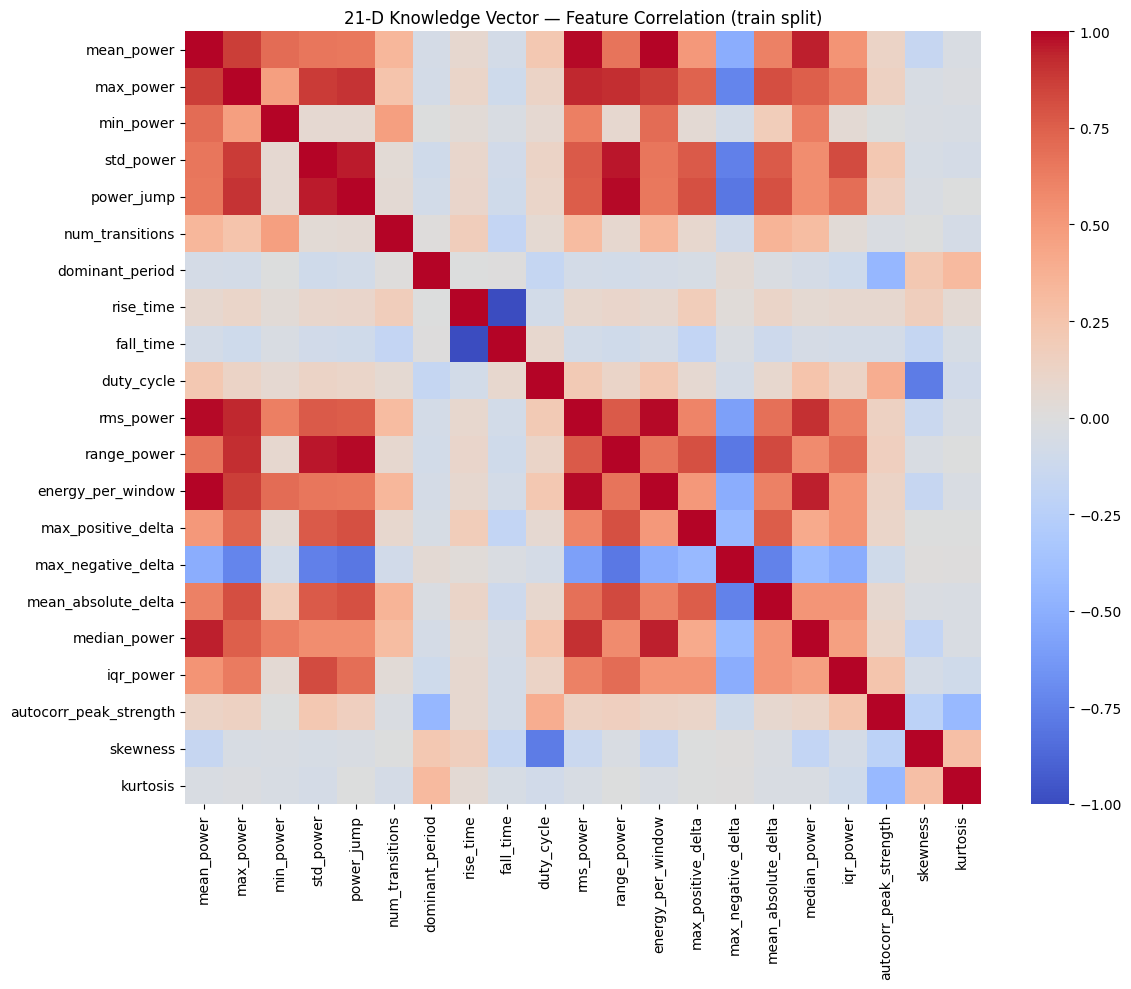

In [ ]:
K_train_df = pd.DataFrame(X_train_know, columns=KNOWLEDGE_FEATURE_NAMES)
corr = K_train_df.corr()

print("Highly correlated knowledge-feature pairs (|r| > 0.85):")
seen = set()
for col in corr.columns:
    for row in corr.index:
        if row == col or (row, col) in seen or (col, row) in seen:
            continue
        seen.add((row, col))
        r = corr.loc[row, col]
        if abs(r) > 0.85:
            print(f"  {row:22s} <-> {col:22s}  r = {r:.3f}")

plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("21-D Knowledge Vector — Feature Correlation (train split)")
plt.tight_layout()
plt.savefig(os.path.join(CONFIG["checkpoint_dir"], "knowledge_correlation.png"), dpi=150)
plt.show()